# knob-senses — servidor TCP de dados

In [39]:
import csv, json, socket, sys, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from pathlib import Path


AXES = ("temperatura_ambiente", "ghit", "jacques", "sin1", "cos1", "PCA_lag1", "sintetico")

HOST = "0.0.0.0"
PORT = 3333
HZ = 1.0

# Um stdout REDIRECIONADO (pipe, arquivo, `jupyter nbconvert --execute`) no
# Windows cai no codepage da locale (cp1252), e ai o travessao do log vira o
# byte 0x97 — que nao e UTF-8 valido. Quem le o pipe com utf-8 quebra no meio.
# Num console interativo ou no Jupyter o Python ja acerta; isto e para o resto.
# O OutStream do Jupyter nao tem reconfigure(), dai o AttributeError no guard.
for _s in (sys.stdout, sys.stderr):
    try:
        _s.reconfigure(encoding="utf-8", errors="replace")
    except (AttributeError, ValueError):
        pass


DATA_SOURCE = Path.cwd().parent / "data" / "splited" / "test.csv"
print(f"dados em {DATA_SOURCE}", flush=True)


ORDEM = Path.cwd().parent / "lib" / "knob-senses-rf" / "normalizacao.json"
_ordem = json.loads(ORDEM.read_text(encoding="utf-8"))

assert tuple(_ordem["features"]) == AXES, (
    "a ordem dos eixos nao bate com a do modelo: "
    f"{_ordem['features']} (modelo) vs {AXES} (servidor). Reordenar aqui quebra a "
    "inferencia em silencio.")

print(f"ordem conferida contra {ORDEM.name}: a rede leva grandeza BRUTA", flush=True)


dados em c:\Users\gusta\Documents\PlatformIO\Projects\knob-senses\data\splited\test.csv
ordem conferida contra normalizacao.json: a rede leva grandeza BRUTA


In [40]:
def load_file(p: Path):
    df = pd.read_csv(p, encoding="utf-8-sig")
    df.columns = [c.strip() for c in df.columns]
    df["datetime"] = pd.to_datetime(df["datetime"])
    df["ano"] = df.datetime.dt.year
    return df

p = DATA_SOURCE
df = load_file(p)
print(f"  {p.parent.name:10} {p.stem:16} {len(df):7} amostras")

  splited    test                4177 amostras


In [41]:
def get_sample_bytes(sample):
    return np.array(sample, dtype=np.float32).tobytes()

In [42]:
for sample in df[df.index < 10].iloc: 
  print(
    np.array([sample[feat] for feat in AXES], dtype=np.float32).tobytes()
  )

b'\x85\xeb\xafA\x9a\xcaFB?\x90\xbaAQ\xea\x8c<N\xf6\x7f?\x00\x00\x00\x00\x00\x00\x00\x00'
b'\xae\xc7\xb9An\xee\x11C}\x08\xd9AQ\xea\x8c<N\xf6\x7f?\xda@\xa7=\x00\x00\x00\x00'
b'\xcdL\xc1A24\xe4B\x89\xbc\xd9AQ\xea\x8c<N\xf6\x7f?~\xb1\x84>\x00\x00\x00\x00'
b'\x02+\xcdA\xff\x10\x98C\xac&\x07BQ\xea\x8c<N\xf6\x7f?\xef\xeen>\x00\x00\x00\x00'
b';\xa6\xd8A\x9f\x04\xd3C[\x84\x19BQ\xea\x8c<N\xf6\x7f?m\xa0\x13?\x00\x00\x00\x00'
b'\x0c\x02\xdcA\xe5\xc1\xd4C\xa0\x91\x1bBQ\xea\x8c<N\xf6\x7f?K~Q?\x00\x00\x00\x00'
b'\xc6\x12\xf1A\x16\xa7[D\xac\x9eVBQ\xea\x8c<N\xf6\x7f?\x8c%O?\x00\x00\x00\x00'
b'\x84\xb2\xfdA\x8eY2D\x9d=KBQ\xea\x8c<N\xf6\x7f?\xc3\xf5\xc0?\x00\x00\x00\x00'
b'\xd3\xcd\xecAGc\xa8C\xeav\x1aBQ\xea\x8c<N\xf6\x7f?\xbfX\x9a?\x00\x00\x00\x00'
b'p\x84\xb9A)aJA\xea9\xbcAQ\xea\x8c<N\xf6\x7f?`,9?\x00\x00\x00\x00'


In [46]:
srv = socket.socket(socket.AF_INET, socket.SOCK_STREAM)

# SO_EXCLUSIVEADDRUSE no Windows, e NAO SO_REUSEADDR. Medido nesta maquina:
#   - com SO_REUSEADDR, um segundo processo consegue fazer bind na porta de
#     um socket que ja esta escutando, em silencio: viram dois servidores na
#     mesma porta e cada cliente cai em um.
#   - SO_EXCLUSIVEADDRUSE bloqueia isso (WSAEADDRINUSE) e, medido tambem,
#     ainda permite reabrir logo apos um cliente desconectar (TIME_WAIT).
# Nos outros sistemas SO_REUSEADDR e o certo: la ele NAO permite sequestro,
# e e ele que evita o TIME_WAIT.
_exclusivo = getattr(socket, "SO_EXCLUSIVEADDRUSE", None)
if _exclusivo is not None:
    srv.setsockopt(socket.SOL_SOCKET, _exclusivo, 1)
else:
    srv.setsockopt(socket.SOL_SOCKET, socket.SO_REUSEADDR, 1)

try:
    srv.bind((HOST, PORT))            # erro de porta estoura AQUI, na celula
    srv.listen(1)
except OSError:
    srv.close()
    raise

# Timeout no listen so para o accept() VOLTAR ao bytecode a cada 0,5 s. Sem
# isso o botao de stop nao funciona: com o accept() bloqueado, o
# KeyboardInterrupt fica pendente e so seria levantado quando chegasse um
# cliente — ou seja, nunca, que e justamente o estado ocioso do servidor.
srv.settimeout(None)

print(f"Server started at {HOST}:{PORT}", flush=True)

# try:
reply = pd.DataFrame({
    'sample': [],
    'pred': [],
    'real': [],
    'err': []
})
errors = []
with open(Path.cwd() / 'model_eval.csv', "w") as model_eval_log:
    model_eval_log.write("sample,real,pred,err,mae\n")
    for sample in df.iloc:
        while True:
            conn, addr = srv.accept()
            conn.setsockopt(socket.IPPROTO_TCP, socket.TCP_NODELAY, 1)
            with conn:
                try:
                    request = conn.recv(1)
                    if request == b"\x01":
                        conn.sendall(get_sample_bytes([sample[feat] for feat in AXES]))
                    elif request == b"\x02":
                        b_pred = conn.recv(4)
                        # Get predicted value
                        pred = np.frombuffer(b_pred, dtype=np.float32)[0]
                        real = sample["PCA"]
                        real_valid = real != 0.0 and not np.isnan(real)
                        sample_stats = dict(
                            sample=sample.datetime,
                            pred=pred,
                            real=real if real_valid else 0.0,
                            err=abs(pred - real) if real_valid else 0.0 
                        )

                        reply.loc[len(reply)] = list(sample_stats.values())
                        print("sample %(sample)s: real=%(real).4f, pred=%(pred).4f, err=%(err).4f" % sample_stats, flush=True)
                        model_eval_log.write(",".join(list(map(str,sample_stats.values()))) + "\n")      
                        break          
                    elif request == b'\x00':
                        break
                    else:
                        print("erro no request", flush=True)
                except socket.timeout:
                    print("error: request timeout", flush=True)
                except OSError:
                    pass                         # cliente desconectou no meio
# except KeyboardInterrupt:
#     print("\ninterrupted", flush=True)
# finally:
#     print("socket closed", flush=True)

Server started at 0.0.0.0:3333
sample 2024-01-01 06:00:00: real=0.0817, pred=0.0979, err=0.0163
sample 2024-01-01 07:00:00: real=0.2592, pred=0.2461, err=0.0131
sample 2024-01-01 08:00:00: real=0.2333, pred=0.2436, err=0.0103
sample 2024-01-01 09:00:00: real=0.5767, pred=0.5773, err=0.0006
sample 2024-01-01 10:00:00: real=0.8183, pred=0.7930, err=0.0253
sample 2024-01-01 11:00:00: real=0.8092, pred=0.7977, err=0.0114
sample 2024-01-01 12:00:00: real=1.5075, pred=1.6155, err=0.1080
sample 2024-01-01 13:00:00: real=1.2058, pred=1.2589, err=0.0530
sample 2024-01-01 14:00:00: real=0.7233, pred=0.6414, err=0.0819
sample 2024-01-01 15:00:00: real=0.0550, pred=0.0570, err=0.0020
sample 2024-01-01 16:00:00: real=0.0200, pred=0.0570, err=0.0370
sample 2024-01-01 17:00:00: real=0.0400, pred=0.0570, err=0.0170
sample 2024-01-02 06:00:00: real=0.1142, pred=0.1788, err=0.0646
sample 2024-01-02 07:00:00: real=0.3042, pred=0.4099, err=0.1057
sample 2024-01-02 08:00:00: real=0.5900, pred=0.6443, err=0

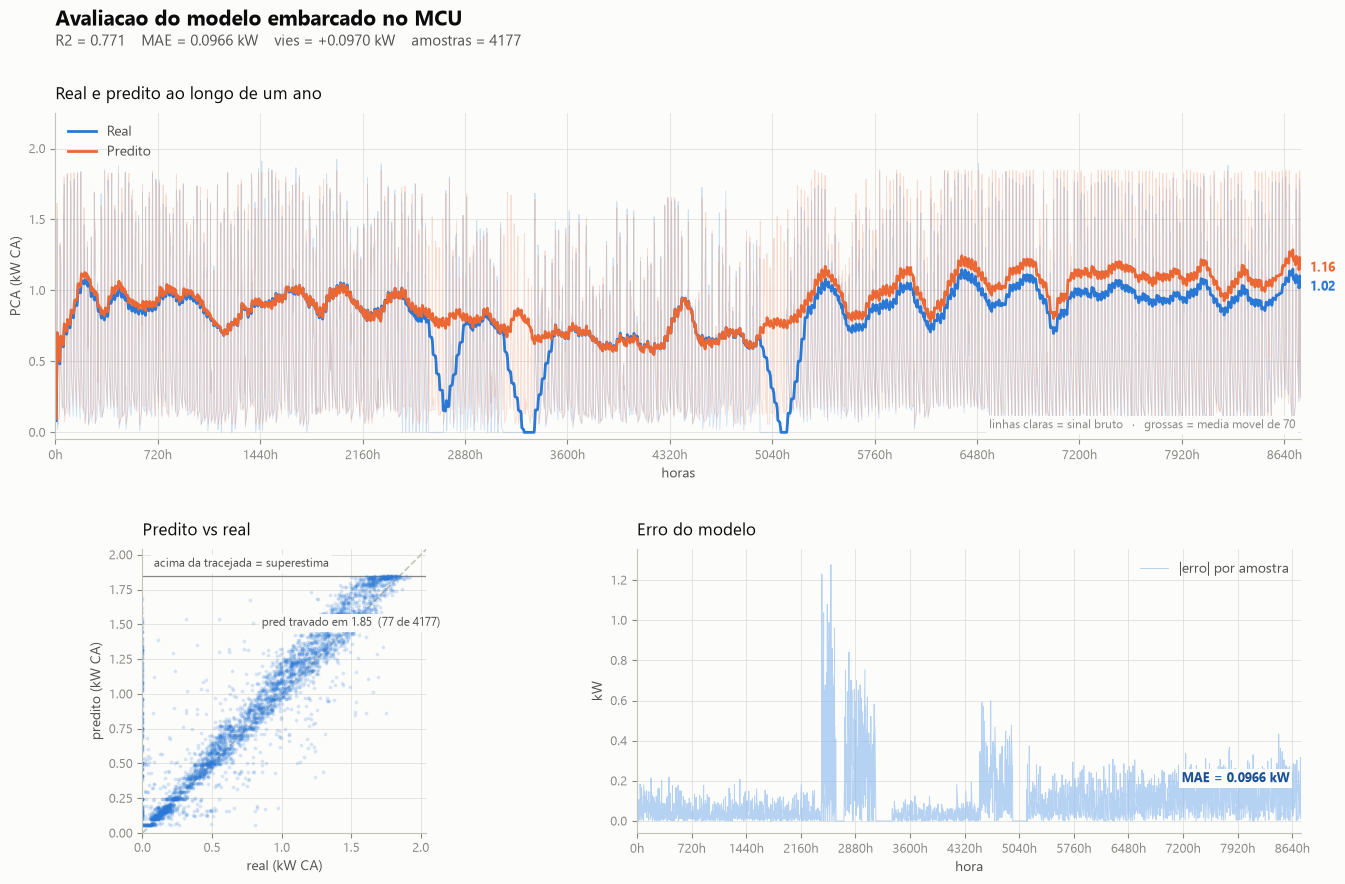

'\nTODO:\n0. Testar novamnete com rede neural (base da conclusão)\n1. Analizar intervalo de 2k amostras - verificar se modelo propaga errors\n2. Verificar se erro esta associado a perda de eficiencia do inversor\n3. Repetir para 1h a frente \n4. Aumentar previsão ate saturar\n'

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from pathlib import Path

SUPERFICIE, TINTA = "#fcfcfb", "#0b0b0b"
TINTA_2, MUDO     = "#52514e", "#898781"
GRADE, EIXO       = "#e1e0d9", "#c3c2b7"
REAL, PREDITO     = "#2a78d6", "#eb6834"   # slots categoricos 1 e 2
ERRO_CLARO, MAE_ESC = "#86b6ef", "#184f95" # rampa azul: degraus 250 e 600

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["Segoe UI", "system-ui", "DejaVu Sans"],
    "figure.facecolor": SUPERFICIE,
    "axes.facecolor": SUPERFICIE,
})

if reply is None:
    df_eval = pd.read_csv(Path.cwd() / "model_eval.csv")
else:
    df_eval = reply.copy()

df_eval["ano"]  = df_eval["sample"].dt.year
df_eval["mes"]  = df_eval["sample"].dt.month
df_eval["doy"]  = df_eval["sample"].dt.dayofyear
df_eval.loc[df_eval["doy"] == 366, "doy"] = 365
df_eval["hora"] = df_eval["sample"].dt.hour
# hora acumulada no ano: hora 0 do dia 1 = 0, ...  (doy-1)*24 + hora
df_eval["hora_ano"] = (df_eval["doy"] - 1) * 24 + df_eval["hora"]

# Media movel proporcional ao tamanho: com 10 mil amostras o sinal bruto
# esconde o vies, que e justamente o que precisa aparecer.
janela = 1 + len(df_eval) // 60
x = df_eval["hora_ano"].to_numpy()
real_l = df_eval["real"].rolling(janela, min_periods=1).mean()
pred_l = df_eval["pred"].rolling(janela, min_periods=1).mean()


np_real = df_eval.real.to_numpy()
np_pred = df_eval.pred.to_numpy()

ss_res = np.sum((np_pred - np_real) ** 2)
ss_tot = ((np_real - np.mean(np_real)) ** 2).sum()
r2   = 1 - (ss_res / ss_tot) 

mae  = df_eval["err"].mean()
vies = (df_eval["pred"] - df_eval["real"]).mean()
teto = df_eval["pred"].max()
no_teto = int((df_eval["pred"] >= teto - 0.01).sum())

fig = plt.figure(figsize=(14, 9))
gs = GridSpec(2, 2, figure=fig, height_ratios=[1.15, 1.0], width_ratios=[1.0, 1.45],
              hspace=0.36, wspace=0.22)
HALO = dict(facecolor=SUPERFICIE, edgecolor="none", pad=2.0)


def enfeitar(ax, titulo, xlabel, ylabel):
    ax.set_title(titulo, color=TINTA, fontsize=12, loc="left", pad=10)
    ax.set_xlabel(xlabel, color=TINTA_2, fontsize=10)
    ax.set_ylabel(ylabel, color=TINTA_2, fontsize=10)
    ax.grid(True, color=GRADE, linewidth=0.6, linestyle="-")   # solida, nunca tracejada
    ax.set_axisbelow(True)
    for lado in ("top", "right"):
        ax.spines[lado].set_visible(False)
    for lado in ("left", "bottom"):
        ax.spines[lado].set_color(EIXO)
    ax.tick_params(colors=MUDO, labelsize=9)


# --- 1. real vs predito ao longo das amostras ------------------------------
ax = fig.add_subplot(gs[0, :])
ax.plot(x, df_eval["real"], color=REAL, lw=0.6, alpha=0.22)
ax.plot(x, df_eval["pred"], color=PREDITO, lw=0.6, alpha=0.22)
ax.plot(x, real_l, color=REAL, lw=2.0, label="Real")
ax.plot(x, pred_l, color=PREDITO, lw=2.0, label="Predito")
enfeitar(ax, "Real e predito ao longo de um ano", "horas", "PCA (kW CA)")
ax.set_xlim(0, 365 * 24)
ticks = np.arange(0, 365 * 24 + 1, 24 * 30)   # ~a cada 30 dias
ax.set_xticks(ticks)
ax.set_xticklabels([f"{int(t)}h" for t in ticks])
# ax.set_xlim(x[0], x[-1] + (x[-1] - x[0]) * 0.06)
ax.set_ylim(-0.05, 2.25)
for serie, cor in ((real_l, REAL), (pred_l, PREDITO)):
    ax.annotate(f"{serie.iloc[-1]:.2f}", (x[-1], serie.iloc[-1]), xytext=(7, 0),
                textcoords="offset points", color=cor, fontsize=9,
                va="center", fontweight="bold")
ax.legend(frameon=False, loc="upper left", fontsize=10, labelcolor=TINTA_2)
ax.text(0.995, 0.025, f"linhas claras = sinal bruto   ·   grossas = media movel de {janela}",
        transform=ax.transAxes, ha="right", va="bottom", color=MUDO,
        fontsize=8.5, bbox=HALO)

# --- 2. predito vs real -- o painel que diagnostica ------------------------
ax = fig.add_subplot(gs[1, 0])
lim = (0, max(df_eval["real"].max(), df_eval["pred"].max()) * 1.06)
ax.plot(lim, lim, color=EIXO, lw=1.2, linestyle="--", zorder=1)   # identidade = limiar
ax.axhline(teto, color=MUDO, lw=0.9, zorder=1)
ax.scatter(df_eval["real"], df_eval["pred"], s=7, color=REAL,
           alpha=0.18, linewidths=0, zorder=2)
ax.annotate(f"pred travado em {teto:.2f}  ({no_teto} de {len(df_eval)})",
            (lim[1] * 0.42, teto), xytext=(0, -36), textcoords="offset points",
            color=TINTA_2, fontsize=8.5, bbox=HALO)
ax.text(lim[1] * 0.04, lim[1] * 0.97, "acima da tracejada = superestima",
        color=TINTA_2, fontsize=8.5, va="top", bbox=HALO)
ax.set_aspect("equal")
ax.set_xlim(lim)
ax.set_ylim(lim)
enfeitar(ax, "Predito vs real", "real (kW CA)", "predito (kW CA)")

# --- 3. erro absoluto e MAE acumulado --------------------------------------
janela = 12
ax = fig.add_subplot(gs[1, 1])
ax.plot(x, df_eval["err"], color=ERRO_CLARO, lw=0.7, alpha=0.6, label="|erro| por amostra")
# err_l = df_eval["err"].rolling(janela, min_periods=1).mean()
# ax.plot(x, err_l, color=MAE_ESC, lw=2.0, label="MAE movel")
enfeitar(ax, "Erro do modelo", "hora", "kW")
ax.set_ylim(-0.06, df_eval.err.max() * 1.06)
ax.set_xlim(0, 365 * 24)
ticks = np.arange(0, 365 * 24 + 1, 24 * 30)   # ~a cada 30 dias
ax.set_xticks(ticks)
ax.set_xticklabels([f"{int(t)}h" for t in ticks])
ax.annotate(f"MAE = {mae:.4f} kW", (x[-1], df_eval.err.mean()), xytext=(-8, 14),
            textcoords="offset points", ha="right", color=MAE_ESC, fontsize=9,
            fontweight="bold", bbox=HALO)
ax.legend(frameon=False, loc="upper right", fontsize=10, labelcolor=TINTA_2)

fig.suptitle("Avaliacao do modelo embarcado no MCU", color=TINTA, fontsize=15,
             x=0.07, ha="left", y=0.985, fontweight="bold")
fig.text(0.07, 0.945,
         f"R2 = {r2:.3f}    MAE = {mae:.4f} kW    vies = {vies:+.4f} kW    amostras = {len(df_eval)}",
         color=TINTA_2, fontsize=11, ha="left")
fig.subplots_adjust(top=0.87, bottom=0.07, left=0.07, right=0.96)
plt.show()


"""
TODO:
0. Testar novamnete com rede neural (base da conclusão)
1. Analizar intervalo de 2k amostras - verificar se modelo propaga errors
2. Verificar se erro esta associado a perda de eficiencia do inversor
3. Repetir para 1h a frente 
4. Aumentar previsão ate saturar
"""
